# CNOT Primitive Consecutive Count Scan

Target logical-failure analysis for each available consecutive-CNOT count in the interval-factor-1 scan.

In [16]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import re
import sys

from IPython.display import Markdown, display

# Work whether Jupyter starts in projects/mp-decoder or its notebooks directory.
PROJECT_DIR = next(
    (
        path
        for path in (Path.cwd(), Path.cwd().parent)
        if (path / "notebooks/analysis_utils.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks."
    )
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    display_finite_size_scaling_fit,
    display_fit_summary,
    fit_finite_size_scaling,
    load_ft_scan,
    plot_rate_scan,
)

DATA_DIR = PROJECT_DIR / "results/cnot_primitive_consecutive/count_scan_interval_1"
COUNT_DIR_PATTERN = re.compile(r"cnot_count_(\d+)$")

# Select the expected data points shown in every target-rate plot.
plot_p_values = [
    0.009,
    0.010,
    0.011,
    0.012,
    0.013,
    0.014,
    0.015,
    0.016,
    0.017,
    0.018,
    0.019,
]
plot_L_values = [5, 7, 9, 13, 19]
expected_repeats = 1

count_dirs = {}
for path in sorted(DATA_DIR.glob("cnot_count_*")):
    match = COUNT_DIR_PATTERN.fullmatch(path.name)
    if match and path.is_dir():
        count_dirs[int(match.group(1))] = path
if not count_dirs:
    raise FileNotFoundError(f"No cnot_count_* directories found under {DATA_DIR}")

cnot_counts = sorted(count_dirs)

print("Data directory:", DATA_DIR)
print("CNOT counts:", cnot_counts)
print("plot L values:", plot_L_values)
print("plot p values:", plot_p_values)
print("expected repeats:", expected_repeats)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Data directory: /Users/nanji1/Library/CloudStorage/OneDrive-Personal/UChicago/research/QEC/projects/mp-decoder/results/cnot_primitive_consecutive/count_scan_interval_1
CNOT counts: [1, 2, 3, 4, 5]
plot L values: [5, 7, 9, 13, 19]
plot p values: [0.009, 0.01, 0.011, 0.012, 0.013, 0.014, 0.015, 0.016, 0.017, 0.018, 0.019]
expected repeats: 1


## Load the count scans

In [17]:
count_scans = {}
for cnot_count, count_dir in count_dirs.items():
    count_scans[cnot_count] = load_ft_scan(
        count_dir,
        p_values=plot_p_values,
        L_values=plot_L_values,
        expected_repeats=expected_repeats,
        failure_fields={"target": "target_logical_failures"},
        scan_label=f"{cnot_count}-CNOT count scan",
    )
    count_scans[cnot_count].print_summary()
    print()

Loaded 55 requested 1-CNOT count scan files; ignored 15 files outside the requested lists
L values: [ 5  7  9 13 19]
p values: [0.009 0.01  0.011 0.012 0.013 0.014 0.015 0.016 0.017 0.018 0.019]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]]

Loaded 55 requested 2-CNOT count scan files; ignored 15 files outside the requested lists
L values: [ 5  7  9 13 19]
p values: [0.009 0.01  0.011 0.012 0.013 0.014 0.015 0.016 0.017 0.018 0.019]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]]

Loaded 55 requested 3-CNOT count scan files; ignored 15 files outside the requested lists
L values: [ 5  7  9 13 19]
p values: [0.009 0.01  0.011 0.012 0.013 0.014 0.015 0.016 0.017 0.018 0.019]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1

## Target failure rate versus physical error rate

### 1 consecutive CNOTs

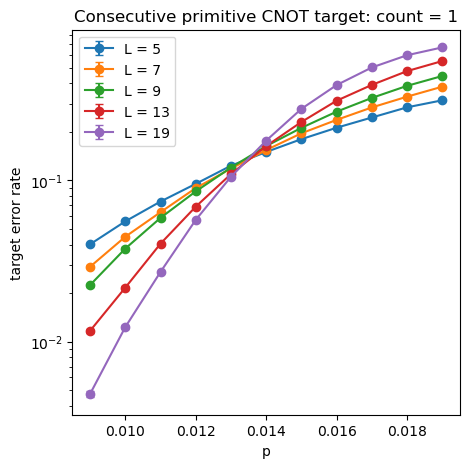

### 2 consecutive CNOTs

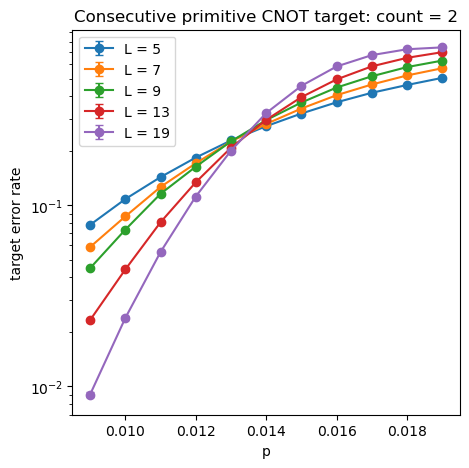

### 3 consecutive CNOTs

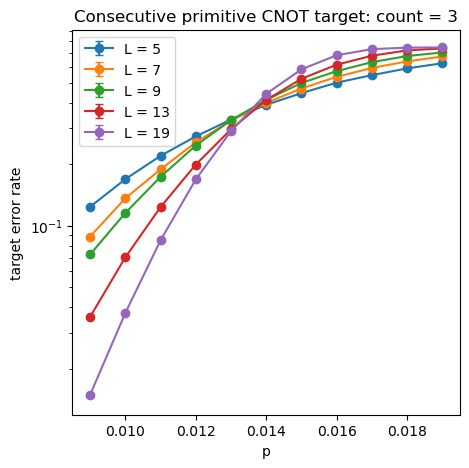

### 4 consecutive CNOTs

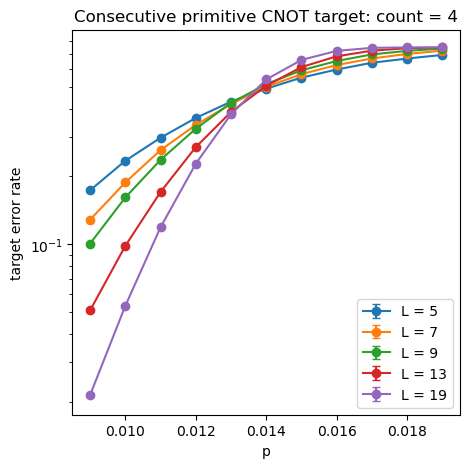

### 5 consecutive CNOTs

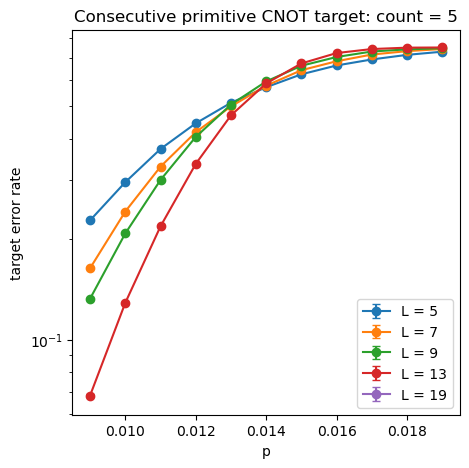

In [18]:
for cnot_count, scan in count_scans.items():
    display(Markdown(f"### {cnot_count} consecutive CNOTs"))
    plot_rate_scan(
        scan,
        rate_name="target",
        title=f"Consecutive primitive CNOT target: count = {cnot_count}",
        ylabel="target error rate",
    )

## Target finite-size-scaling fits

Set `fit_p_values` and `fit_L_values` below to choose the exact data points included in every fit. These fits use the same degree-4 scaling polynomial as `cnot_primitive_consecutive_analysis.ipynb`.

#### Finite-size scaling fit: 1 consecutive CNOTs — target

Degree-4 model: $P_L(p)=A+Bx+Cx^{2}+Dx^{3}+Ex^{4}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.011, 0.019]$ and $L \in [5, 7, 9, 13, 19]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01338(1) |
| $p_c$ (%) | 1.338(1) |
| $\nu$ | 1.296(7) |
| $A$ | 0.1323(6) |
| $B$ | 7.60(6) |
| $C$ | 123(3) |
| $D$ | -738(50) |
| $E$ | -13897(1263) |
| $\chi^2 / \mathrm{dof}$ | 292.25 / 38 = 7.69 |
| goodness-of-fit $p$-value | 5.68e-41 |

> **Fit-quality warning:** the degree-4 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

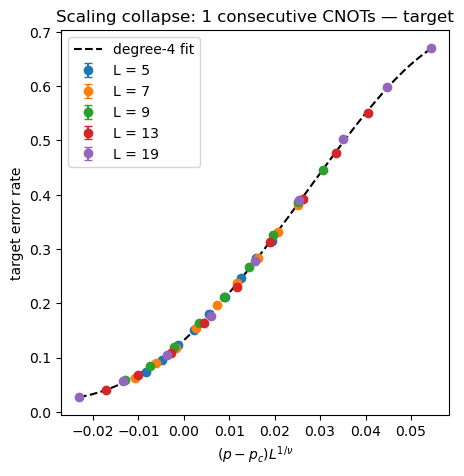

#### Finite-size scaling fit: 2 consecutive CNOTs — target

Degree-4 model: $P_L(p)=A+Bx+Cx^{2}+Dx^{3}+Ex^{4}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.011, 0.019]$ and $L \in [5, 7, 9, 13, 19]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01334(1) |
| $p_c$ (%) | 1.334(1) |
| $\nu$ | 1.333(7) |
| $A$ | 0.2437(8) |
| $B$ | 13.2(1) |
| $C$ | 111(3) |
| $D$ | -4336(111) |
| $E$ | 16063(1376) |
| $\chi^2 / \mathrm{dof}$ | 488.83 / 38 = 12.86 |
| goodness-of-fit $p$-value | 1.16e-79 |

> **Fit-quality warning:** the degree-4 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

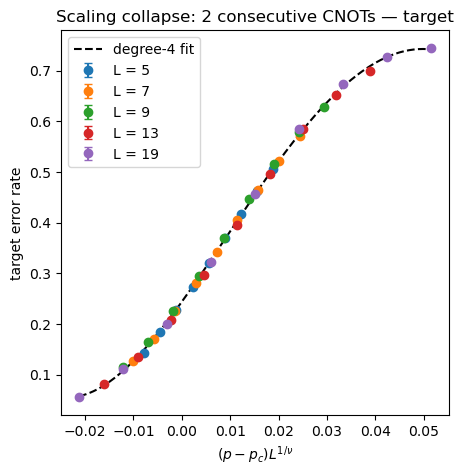

#### Finite-size scaling fit: 3 consecutive CNOTs — target

Degree-4 model: $P_L(p)=A+Bx+Cx^{2}+Dx^{3}+Ex^{4}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.011, 0.019]$ and $L \in [5, 7, 9, 13, 19]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01340(1) |
| $p_c$ (%) | 1.340(1) |
| $\nu$ | 1.343(7) |
| $A$ | 0.3569(9) |
| $B$ | 16.9(1) |
| $C$ | -3(2) |
| $D$ | -7817(207) |
| $E$ | 84763(3052) |
| $\chi^2 / \mathrm{dof}$ | 619.95 / 38 = 16.31 |
| goodness-of-fit $p$-value | 2.77e-106 |

> **Fit-quality warning:** the degree-4 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

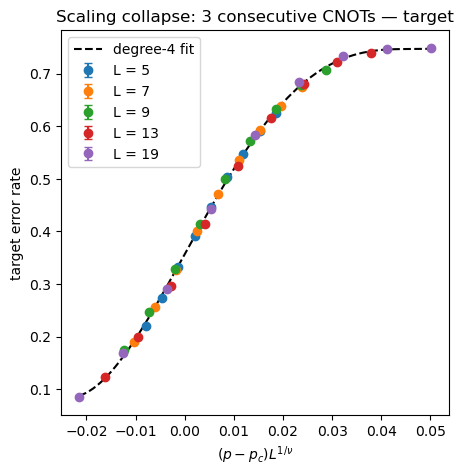

#### Finite-size scaling fit: 4 consecutive CNOTs — target

Degree-4 model: $P_L(p)=A+Bx+Cx^{2}+Dx^{3}+Ex^{4}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.011, 0.019]$ and $L \in [5, 7, 9, 13, 19]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01350(1) |
| $p_c$ (%) | 1.350(1) |
| $\nu$ | 1.415(9) |
| $A$ | 0.460(1) |
| $B$ | 19.2(2) |
| $C$ | -172(5) |
| $D$ | -10340(300) |
| $E$ | 176887(7255) |
| $\chi^2 / \mathrm{dof}$ | 594.57 / 38 = 15.65 |
| goodness-of-fit $p$-value | 4.24e-101 |

> **Fit-quality warning:** the degree-4 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

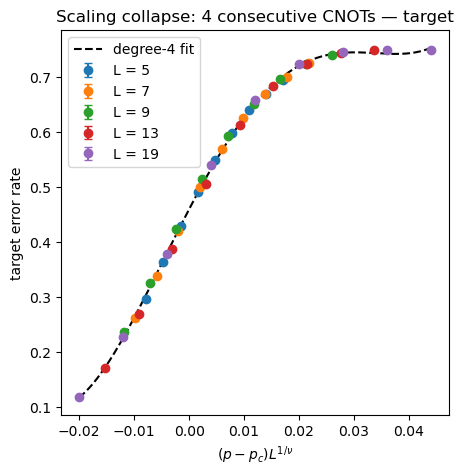

#### Finite-size scaling fit: 5 consecutive CNOTs — target

Degree-4 model: $P_L(p)=A+Bx+Cx^{2}+Dx^{3}+Ex^{4}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.011, 0.019]$ and $L \in [5, 7, 9, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.01360(2) |
| $p_c$ (%) | 1.360(2) |
| $\nu$ | 1.45(2) |
| $A$ | 0.549(2) |
| $B$ | 18.9(3) |
| $C$ | -392(16) |
| $D$ | -9660(441) |
| $E$ | 303396(20437) |
| $\chi^2 / \mathrm{dof}$ | 447.90 / 29 = 15.44 |
| goodness-of-fit $p$-value | 1.35e-76 |

> **Fit-quality warning:** the degree-4 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

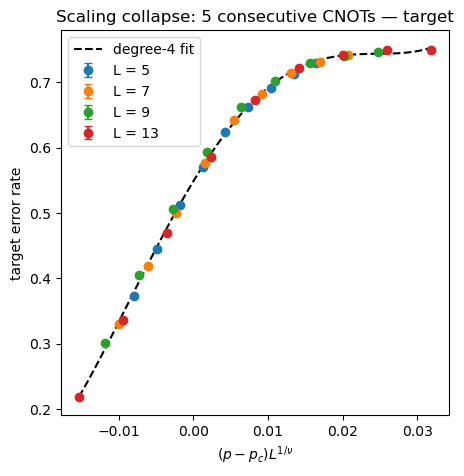

In [19]:
# Select the exact p and L groups used by every target fit.
fit_p_values = [
    0.011,
    0.012,
    0.013,
    0.014,
    0.015,
    0.016,
    0.017,
    0.018,
    0.019,
]
fit_L_values = [5, 7, 9, 13, 19]
fit_degree = 4
target_fits = []

for cnot_count, count_dir in count_dirs.items():
    fit_scan = load_ft_scan(
        count_dir,
        p_values=fit_p_values,
        L_values=fit_L_values,
        expected_repeats=expected_repeats,
        failure_fields={"target": "target_logical_failures"},
        scan_label=f"{cnot_count}-CNOT target fit",
    )
    fit = fit_finite_size_scaling(
        fit_scan,
        rate_name="target",
        label=f"{cnot_count} consecutive CNOTs — target",
        polynomial_degree=fit_degree,
        fit_p_range=(min(fit_p_values), max(fit_p_values)),
        min_L=min(fit_L_values),
    )
    target_fits.append(fit)
    display_finite_size_scaling_fit(fit, "target error rate")

## Final target-threshold summary

In [20]:
display_fit_summary(
    target_fits,
    title="Consecutive primitive CNOT target-threshold summary",
)

## Consecutive primitive CNOT target-threshold summary

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| 1 consecutive CNOTs — target | 4 | 0.01338(1) | 1.338(1) | 1.296(7) | 7.69 | 5.68e-41 |
| 2 consecutive CNOTs — target | 4 | 0.01334(1) | 1.334(1) | 1.333(7) | 12.86 | 1.16e-79 |
| 3 consecutive CNOTs — target | 4 | 0.01340(1) | 1.340(1) | 1.343(7) | 16.31 | 2.77e-106 |
| 4 consecutive CNOTs — target | 4 | 0.01350(1) | 1.350(1) | 1.415(9) | 15.65 | 4.24e-101 |
| 5 consecutive CNOTs — target | 4 | 0.01360(2) | 1.360(2) | 1.45(2) | 15.44 | 1.35e-76 |